# Аудит качества A/B-эксперимента

**Цель:** проверить корректность рандомизации и качество данных, выявить скрытые нарушения, принять решение о валидности и показать пример коррекции ковариатного дисбаланса.

**Данные:** файл `experiment_data.csv`, сгенерирован однократно скриптом `generate_data.py`. SEED = **3523534**. Для увеличения мощности тестов использована выборка 9000–9999 человек; вероятность назначения в тест заменена на `clip(0.36 + 0.55 × pre_activity / max(pre_activity), 0, 1)`. Остальная логика соответствует условию. Важный нюанс: промежуточное назначение `variant` с вероятностями 40/60 **перезаписывается** значениями `variant2`; поэтому фактическое SRM обусловлено именно финальным назначением, а не первой командой `np.random.choice`.

> Порог значимости: α = 0.05. Отдельные статистические тесты не доказывают причинность. При нарушенной рандомизации результаты метрик трактуются осторожно.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chisquare, ttest_ind, mannwhitneyu, fisher_exact, chi2_contingency
from statsmodels.stats.proportion import confint_proportions_2indep
from sklearn.linear_model import LogisticRegression

sns.set_theme(style="whitegrid", palette="colorblind")
ALPHA = 0.05
DATA_PATH = Path("experiment_data.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("ab_experiment/experiment_data.csv")
assert DATA_PATH.exists(), "Поместите experiment_data.csv рядом с ноутбуком"
df = pd.read_csv(DATA_PATH, parse_dates=["date"])
display(df.head())

,user_id,variant,converted,error_flag,pre_activity,date
0,0,control,0,0,5,2026-05-14
1,1,control,0,0,2,2026-05-10
2,2,test,0,0,13,2026-05-07
3,3,control,0,0,19,2026-05-09
4,4,test,0,0,5,2026-05-14


## 1. Базовая диагностика и качество данных

Проверяем схему, дубликаты `user_id`, пропуски, допустимость бинарных метрик и категорий, а также сводку по вариантам.

In [2]:
required = {"user_id", "variant", "converted", "error_flag", "pre_activity", "date"}
assert required.issubset(df.columns), f"Нет колонок: {required - set(df.columns)}"
print("Размер таблицы:", df.shape)
print("Пропуски по столбцам:\n", df.isna().sum().to_string())
print("Дубли user_id:", df.user_id.duplicated().sum())
print("Даты:", df.date.min().date(), "—", df.date.max().date())
assert not df.isna().any().any()
assert df.user_id.is_unique
assert set(df.variant.unique()) == {"control", "test"}
assert df.converted.isin([0, 1]).all() and df.error_flag.isin([0, 1]).all()
assert df.pre_activity.ge(0).all()

summary = df.groupby("variant", sort=True).agg(
    users=("user_id", "size"),
    conversions=("converted", "sum"),
    conversion_rate=("converted", "mean"),
    errors=("error_flag", "sum"),
    error_rate=("error_flag", "mean"),
    mean_pre_activity=("pre_activity", "mean"),
    median_pre_activity=("pre_activity", "median"),
)
summary["share"] = summary.users / len(df)
display(summary.style.format({"conversion_rate":"{:.3%}", "error_rate":"{:.3%}", "share":"{:.2%}", "mean_pre_activity":"{:.2f}"}))
c = df.loc[df.variant == "control"]
t = df.loc[df.variant == "test"]

Размер таблицы: (9725, 6)
Пропуски по столбцам:
 user_id         0
variant         0
converted       0
error_flag      0
pre_activity    0
date            0
Дубли user_id: 0
Даты: 2026-05-01 — 2026-05-14


,users,conversions,conversion_rate,errors,error_rate,mean_pre_activity,median_pre_activity,share
variant,,,,,,,,
control,5740,274,4.774%,57,0.993%,8.58,6.000000,59.02%
test,3985,218,5.471%,65,1.631%,10.71,7.000000,40.98%


## 2. SRM: проверка соотношения 50/50

**H₀:** доли назначения в группы равны 50%/50%. При таком нуле ожидаемые численности = N/2. χ² goodness-of-fit с одной степенью свободы.

In [3]:
observed = np.array([len(c), len(t)])
expected = np.repeat(len(df) / 2, 2)
srm_stat, srm_p = chisquare(f_obs=observed, f_exp=expected)
srm_warning = srm_p < ALPHA
print(f"Факт control/test: {len(c)}/{len(t)} (доли {len(c)/len(df):.2%}/{len(t)/len(df):.2%})")
print(f"χ² = {srm_stat:.3f}, p-value = {srm_p:.3e}")
if srm_warning:
    print("⚠ SRM обнаружен")
else:
    print("SRM статистически не обнаружен")

Факт control/test: 5740/3985 (доли 59.02%/40.98%)
χ² = 316.712, p-value = 7.535e-71
⚠ SRM обнаружен


## 3. Баланс ковариаты `pre_activity`

Признак неотрицателен и имеет асимметричное распределение; вместе с устойчивым к ненормальности U-тестом Манна–Уитни используем **t-test Уэлча** для сравнения средних. Также считаем стандартизованную разность средних (SMD); при правильной рандомизации ожидаем баланс в среднем, но единичная выборка может случайно отличаться.

In [4]:
welch = ttest_ind(t.pre_activity, c.pre_activity, equal_var=False)
mann_whitney = mannwhitneyu(t.pre_activity, c.pre_activity, alternative="two-sided")
pooled_sd = np.sqrt((t.pre_activity.var(ddof=1) + c.pre_activity.var(ddof=1)) / 2)
smd_before = (t.pre_activity.mean() - c.pre_activity.mean()) / pooled_sd
cov_warning = (welch.pvalue < ALPHA) or (mann_whitney.pvalue < ALPHA)
print(f"Средняя активность: control={c.pre_activity.mean():.3f}, test={t.pre_activity.mean():.3f}")
print(f"t-test Уэлча p={welch.pvalue:.3e}; U-тест p={mann_whitney.pvalue:.3e}")
print(f"SMD = {smd_before:.3f}")
if cov_warning:
    print("⚠ Дисбаланс по pre_activity — возможен confounder")
else:
    print("Статистически значимого дисбаланса не выявлено")

Средняя активность: control=8.578, test=10.714
t-test Уэлча p=2.421e-23; U-тест p=1.184e-20
SMD = 0.210
⚠ Дисбаланс по pre_activity — возможен confounder


## 4. Guardrail: ошибки загрузки

Проверяем разницу в долях ошибок. Из-за относительно редких событий применяем **двусторонний точный тест Фишера**, считаем абсолютное изменение в процентных пунктах, отношение рисков и доверительный интервал для разности долей (Newcombe). Значимое ухудшение guardrail — самостоятельное основание для остановки.

In [5]:
ct = np.array([[int(t.error_flag.sum()), len(t)-int(t.error_flag.sum())],
               [int(c.error_flag.sum()), len(c)-int(c.error_flag.sum())]])
odds_ratio, guardrail_p = fisher_exact(ct, alternative="two-sided")
rate_t, rate_c = t.error_flag.mean(), c.error_flag.mean()
err_diff = rate_t - rate_c
err_rr = rate_t / rate_c if rate_c > 0 else np.inf
ci_err = confint_proportions_2indep(int(t.error_flag.sum()), len(t),
                                    int(c.error_flag.sum()), len(c),
                                    compare="diff", method="newcomb")
guardrail_warning = (guardrail_p < ALPHA) and (rate_t > rate_c)
print(f"Ошибки: control={c.error_flag.sum()}/{len(c)} ({rate_c:.3%}); test={t.error_flag.sum()}/{len(t)} ({rate_t:.3%})")
print(f"Разница = {err_diff*100:+.3f} п.п.; RR = {err_rr:.3f}")
print(f"95% ДИ разницы = [{ci_err[0]*100:.3f}, {ci_err[1]*100:.3f}] п.п.; Fisher p={guardrail_p:.5f}")
if guardrail_warning:
    print("⚠ Guardrail: частота ошибок значимо выросла в тесте")
elif guardrail_p < ALPHA:
    print("Есть значимое изменение guardrail, без ухудшения в тесте")
else:
    print("Значимого различия guardrail не обнаружено")

Ошибки: control=57/5740 (0.993%); test=65/3985 (1.631%)
Разница = +0.638 п.п.; RR = 1.643
95% ДИ разницы = [0.183, 1.135] п.п.; Fisher p=0.00699
⚠ Guardrail: частота ошибок значимо выросла в тесте


## 5. Визуализация и временная диагностика

Графики показывают: (1) разрыв между фактическим и ожидаемым размером групп; (2) распределения активности, включая правый хвост; (3) различия в долях ошибок; (4) динамику долей ошибок по датам. Дневные точки чувствительны к небольшому числу ошибок, поэтому их нельзя считать полноценным отдельным тестом.

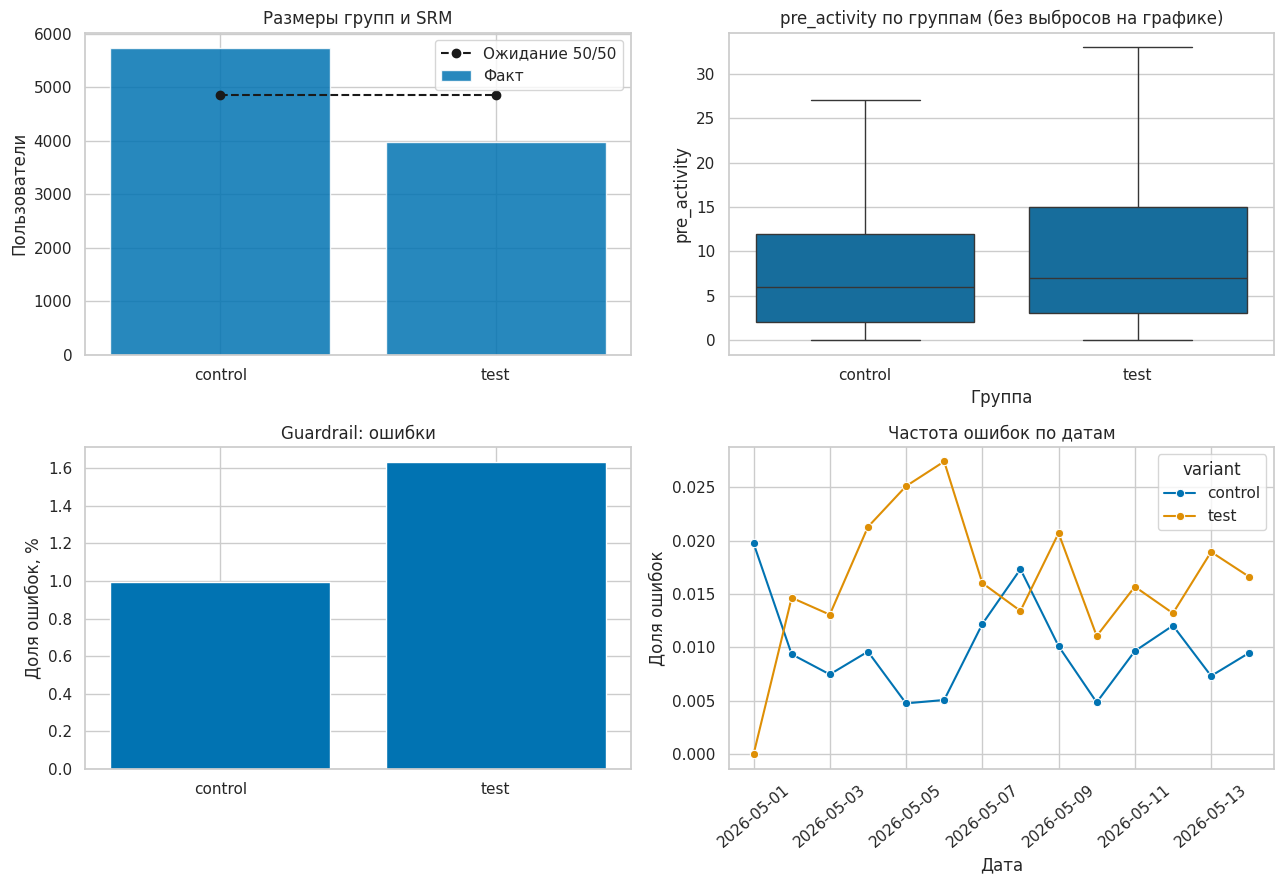

In [6]:
fig, axs = plt.subplots(2, 2, figsize=(13, 9))
labels = ["control", "test"]
axs[0,0].bar(labels, observed, label="Факт", alpha=.85)
axs[0,0].plot(labels, expected, "k--o", label="Ожидание 50/50")
axs[0,0].set(title="Размеры групп и SRM", ylabel="Пользователи")
axs[0,0].legend()
sns.boxplot(data=df, x="variant", y="pre_activity", order=labels, ax=axs[0,1], showfliers=False)
axs[0,1].set(title="pre_activity по группам (без выбросов на графике)", xlabel="Группа")
axs[1,0].bar(labels, [rate_c * 100, rate_t * 100])
axs[1,0].set(title="Guardrail: ошибки", ylabel="Доля ошибок, %")
daily = df.groupby(["date", "variant"], as_index=False)["error_flag"].mean()
sns.lineplot(data=daily, x="date", y="error_flag", hue="variant", marker="o", ax=axs[1,1])
axs[1,1].set(title="Частота ошибок по датам", ylabel="Доля ошибок", xlabel="Дата")
axs[1,1].tick_params(axis="x", rotation=40)
plt.tight_layout()
plt.show()

## 6. Правило валидности и первичная метрика

Если **хотя бы один** из трех сигналов обнаружен, эксперимент признаётся невалидным. Анализ конверсии в этом случае выводим **только для диагностики** и не трактуем как причинный эффект. При отсутствии сигналов тот же χ²-тест конверсии становится стандартным итоговым тестом.

In [7]:
invalid = srm_warning or cov_warning or guardrail_warning
print("Статусы:", {"SRM": bool(srm_warning), "pre_activity": bool(cov_warning),
                      "guardrail deterioration": bool(guardrail_warning)})
if invalid:
    print("❌ ЭКСПЕРИМЕНТ НЕ ВАЛИДЕН. Остановить тест, исправить ошибки, перезапустить.")
else:
    print("✅ Критичных предупреждений нет: можно анализировать основную метрику.")

conversion_table = pd.crosstab(df.variant, df.converted).reindex(index=labels, columns=[0,1], fill_value=0)
chi_conv, p_conv, _, _ = chi2_contingency(conversion_table, correction=False)
print(f"Конверсия control={c.converted.mean():.3%}; test={t.converted.mean():.3%}")
print(f"Разница={(t.converted.mean()-c.converted.mean())*100:+.3f} п.п.; χ² p={p_conv:.5f}")
if invalid:
    print("ВНИМАНИЕ: p-value конверсии только диагностический, вывод об эффекте делать нельзя.")
else:
    print("Значимость конверсии:", "p < 0.05" if p_conv < ALPHA else "p ≥ 0.05")

Статусы: {'SRM': True, 'pre_activity': True, 'guardrail deterioration': True}
❌ ЭКСПЕРИМЕНТ НЕ ВАЛИДЕН. Остановить тест, исправить ошибки, перезапустить.
Конверсия control=4.774%; test=5.471%
Разница=+0.697 п.п.; χ² p=0.12298
ВНИМАНИЕ: p-value конверсии только диагностический, вывод об эффекте делать нельзя.


## 7. Бонус: балансировка через propensity-score weighting (IPW)

Обучаем логистическую регрессию для **оценки вероятности попасть в тест по pre_activity**, затем строим стабилизированные inverse-probability weights. Сравниваем взвешенные средние ковариаты (SMD), размеры эффективной выборки и взвешенные доли конверсии. **Это иллюстрация метода, а не восстановление настоящей рандомизации.** Поскольку само назначение неслучайно и guardrail ухудшен, даже после балансировки эксперимент по правилам задания остаётся невалидным.

In [8]:
assigned = (df.variant == "test").astype(int).to_numpy()
X = df[["pre_activity"]].to_numpy()
model = LogisticRegression(max_iter=1000)
model.fit(X, assigned)
ps = np.clip(model.predict_proba(X)[:, 1], 0.05, 0.95)
p_t = assigned.mean()
weights = np.where(assigned == 1, p_t / ps, (1-p_t) / (1-ps))

def weighted_mean(values, w):
    return np.average(np.asarray(values), weights=w)

wt = weights[assigned == 1]
wc = weights[assigned == 0]
mean_t = weighted_mean(t.pre_activity, wt)
mean_c = weighted_mean(c.pre_activity, wc)
smd_after = (mean_t - mean_c) / pooled_sd
conv_t_adj = weighted_mean(t.converted, wt)
conv_c_adj = weighted_mean(c.converted, wc)
ess_t = wt.sum()**2 / (wt**2).sum()
ess_c = wc.sum()**2 / (wc**2).sum()

results = pd.DataFrame({
    "До IPW": [t.pre_activity.mean(), c.pre_activity.mean(), smd_before,
               t.converted.mean(), c.converted.mean(), t.converted.mean()-c.converted.mean()],
    "После IPW": [mean_t, mean_c, smd_after, conv_t_adj, conv_c_adj, conv_t_adj-conv_c_adj],
}, index=["Средняя активность test", "Средняя активность control", "SMD (активность)",
          "Конверсия test", "Конверсия control", "Разница конверсий"])
display(results.round(5))
print(f"Effective sample size: control={ess_c:.0f} из {len(c)}, test={ess_t:.0f} из {len(t)}")
print("IPW исправляет наблюдаемый дисбаланс, но не SRM и не сам факт ошибочного назначения.")
print("Окончательное решение: эксперимент НЕ ВАЛИДЕН, необходим перезапуск.")

,До IPW,После IPW
Средняя активность test,10.71393,9.46696
Средняя активность control,8.57805,9.45706
SMD (активность),0.20958,0.00097
Конверсия test,0.05471,0.05521
Конверсия control,0.04774,0.04777
Разница конверсий,0.00697,0.00744


Effective sample size: control=5685 из 5740, test=3934 из 3985
IPW исправляет наблюдаемый дисбаланс, но не SRM и не сам факт ошибочного назначения.
Окончательное решение: эксперимент НЕ ВАЛИДЕН, необходим перезапуск.


## 8. Интерпретация и рекомендации

**Проблема №1 — SRM.** Доли пользователей существенно отличаются от ожидаемых 50/50; статистический χ²-тест обнаруживает несоответствие. Важно, что здесь основная причина — не строка `np.random.choice(..., p=[.4, .6])`, которая перезаписана, а окончательная вероятность `prob_test`, зависящая от активности и не соответствующая 0.5.

**Проблема №2 — зависимость назначения от pre_activity.** В тесте доля активных пользователей выше. Поскольку вероятность конверсии тоже растёт вместе с `pre_activity`, сырое различие конверсий может возникать **без причинного эффекта**. Проверки выявляют ассоциацию и дисбаланс; источник конфаундинга известен здесь по генератору.

**Проблема №3 — guardrail.** Вероятность ошибок задана генератором 1% в контроле и 2% в тесте. В случайной реализации фактические проценты отличаются; проверяем **фактические**, а не заданные вероятности. Хотя генератор не добавлял эффект в конверсию, в guardrail он намеренно добавляет различие по варианту — это не противоречие.

**Практическое исправление:** исправить распределитель на независимый от характеристик пользователя механизм `rng.choice(["control", "test"], p=[0.5, 0.5])`, проверить единицу рандомизации и логирование попадания в группы, исследовать причины ошибок загрузки и устранить их до повторного запуска. Запланировать мониторинг SRM и guardrail с корректными процедурами последовательного контроля. Не удалять наблюдения постфактум ради получения благоприятного p-value: это создаёт selection bias.

**Ограничения:** незначимый тест не доказывает равенство долей или отсутствие проблем; серия тестов требует осторожной интерпретации. IPW корректирует лишь измеренные ковариаты, чувствителен к модели propensity score и не делает исходное нарушение дизайна допустимым.

**Решение:** **остановить тест, исправить ошибки, перезапустить**. Инференс по конверсии возможен после восстановления валидного дизайна.